# B1 — Planification des séances de radiothérapie avec CP-SAT

**Problème.** Un service de radiothérapie dispose de plusieurs accélérateurs (LINAC). Chaque patient reçoit une prescription de *N* séances quotidiennes (20 à 35, moins pour les urgences palliatives) qui doivent avoir lieu :
1. sur des **jours ouvrés consécutifs**,
2. sur la **même machine** (compatible avec la technique prescrite),
3. au **même créneau horaire**,
4. en commençant **avant un délai maximal** qui dépend de la priorité (urgent / prioritaire / standard).

**Démarche.** Générateur d'instances → baseline « premier arrivé, premier servi » (FCFS) → modèle CP-SAT → vérificateur indépendant → comparaison.

In [1]:
%matplotlib inline
# pip install ortools matplotlib pandas   (si nécessaire)
import pandas as pd
from instance import generer_instance, PRIORITES, TECHNIQUES
from fcfs import planifier_fcfs
from modele_cpsat import resoudre_cpsat, cout_planning, POIDS_PRIORITE, PENALITE_RETARD
from verificateur import planning_vers_seances, verifier, exporter_csv
from metriques import indicateurs, tableau_comparatif
from graphiques import gantt, comparaison_attentes

## 1. Générateur d'instances

Le temps est compté en **jours ouvrés** (jour 0 = lundi semaine 1, jour 5 = lundi semaine 2…). Ainsi « séances consécutives les jours ouvrés » = un bloc de jours contigus ; les week-ends sont gérés automatiquement.

- Parc hétérogène : LINAC-A (3D seulement), LINAC-B (3D + VMAT), LINAC-C (tout, y compris VMAT complexe dont les séances durent 2 créneaux).
- Arrivées de patients selon un processus de Poisson, calibré pour une **charge** donnée (fraction de la capacité).
- Des patients **déjà en traitement** au jour 0 occupent une partie des créneaux (planning figé).

In [2]:
pd.DataFrame(PRIORITES).T

,nom,attente_max,preparation,proportion,seances
1,urgent,2,0,0.15,"(5, 10)"
2,prioritaire,10,3,0.35,"(20, 35)"
3,standard,20,5,0.5,"(20, 35)"


In [3]:
inst = generer_instance(graine=0, nb_machines=3, nb_semaines=8, charge=0.9)
print(inst.resume())
pd.DataFrame([vars(p) for p in inst.nouveaux_patients()]).drop(columns=["fixe"]).head(10)

Instance 'inst_s0_m3_w8_c90' : 3 machine(s), 20 créneaux/jour, 40 jours ouvrés (8 semaines)
  103 nouveaux patients urgent=11, prioritaire=32, standard=60
  33 patients déjà en traitement au jour 0
  Machine 0 (LINAC-A) : 3D
  Machine 1 (LINAC-B) : 3D, VMAT
  Machine 2 (LINAC-C) : 3D, VMAT, VMAT_complexe


,id,arrivee,priorite,technique,nb_seances,duree,machines_compatibles,debut_au_plus_tot,date_limite
0,33,0,3,3D,26,1,"[0, 1, 2]",5,20
1,34,0,3,VMAT,34,1,"[1, 2]",5,20
2,35,0,1,3D,10,1,"[0, 1, 2]",0,2
3,36,0,3,VMAT_complexe,30,2,[2],5,20
4,37,0,1,3D,10,1,"[0, 1, 2]",0,2
5,38,1,3,VMAT,26,1,"[1, 2]",6,21
6,39,1,2,3D,33,1,"[0, 1, 2]",4,11
7,40,1,3,VMAT_complexe,35,2,[2],6,21
8,41,2,3,VMAT,24,1,"[1, 2]",7,22
9,42,2,1,3D,10,1,"[0, 1, 2]",2,4


## 2. Baseline : premier arrivé, premier servi

Chaque patient, dans l'ordre d'arrivée, prend la **première place libre** (jour le plus tôt, puis machine, puis créneau). Aucun retour en arrière. Variante `FCFS+prio` : à jour égal, les urgents passent d'abord.

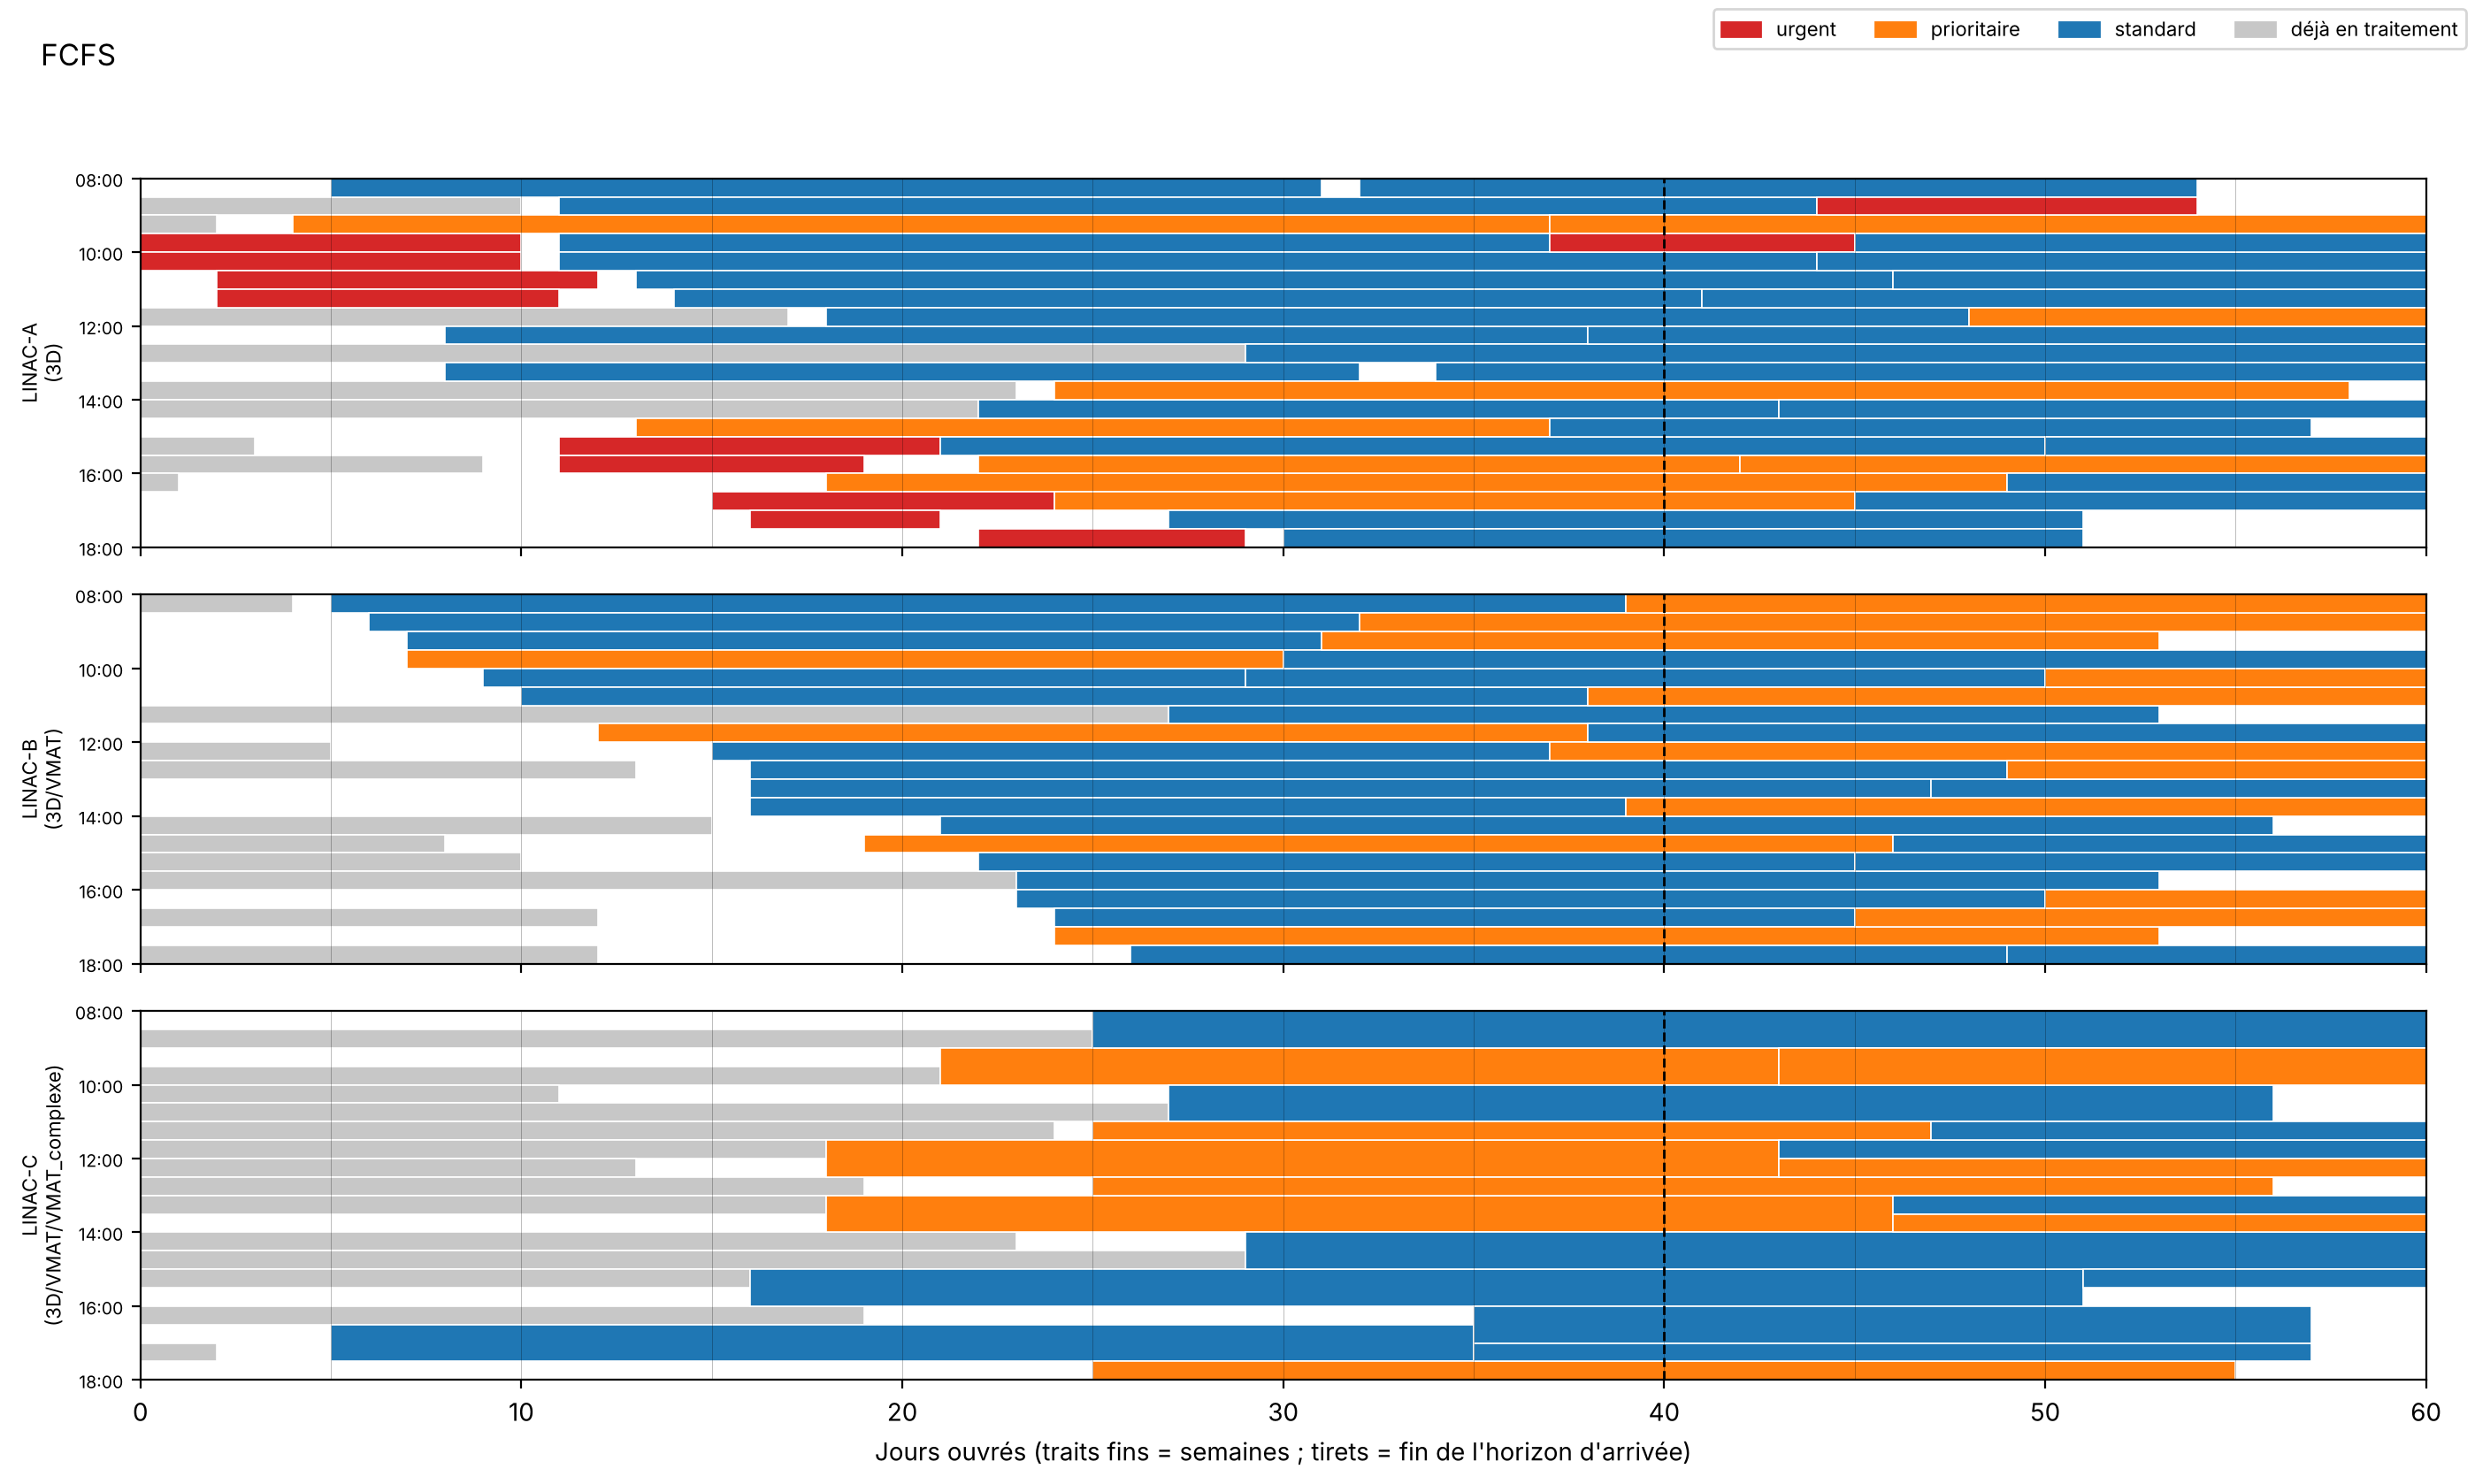

In [4]:
pl_fcfs = planifier_fcfs(inst, "arrivee")
pl_fcfs_prio = planifier_fcfs(inst, "priorite")
gantt(inst, pl_fcfs, "FCFS");

## 3. Modèle CP-SAT

**Variables** (par patient *p*) : `debut[p]` (jour de la 1re séance), `creneau[p]`, et un booléen `presence[p,m]` par machine compatible.

**Idée clé** : sur la grille *jours × créneaux* d'une machine, un patient est un **rectangle** de largeur `nb_seances` et de hauteur `duree`. Les contraintes 1-2-3 sont donc vraies *par construction* ; il reste :
- `AddExactlyOne(presence[p,m])` : une seule machine ;
- `AddNoOverlap2D` par machine, avec des intervalles **optionnels** : pas deux patients au même endroit ;
- domaine de `debut[p]` ≥ arrivée + préparation.

**Objectif** : `min Σ poids[prio]·attente + 100·Σ poids[prio]·retard`, avec poids = {1: 10, 2: 3, 3: 1} et retard = max(0, début − date limite). Le délai maximal est une contrainte *molle* (option `delai_strict=True` pour la rendre dure).

On donne la meilleure solution FCFS comme **hint** : CP-SAT ne peut que l'améliorer.

{'statut': 'FEASIBLE', 'temps_s': 30.0, 'nb_variables': 654, 'nb_contraintes': 800, 'objectif': 6483.0, 'borne_inf': 588.0, 'gap_%': 90.93}


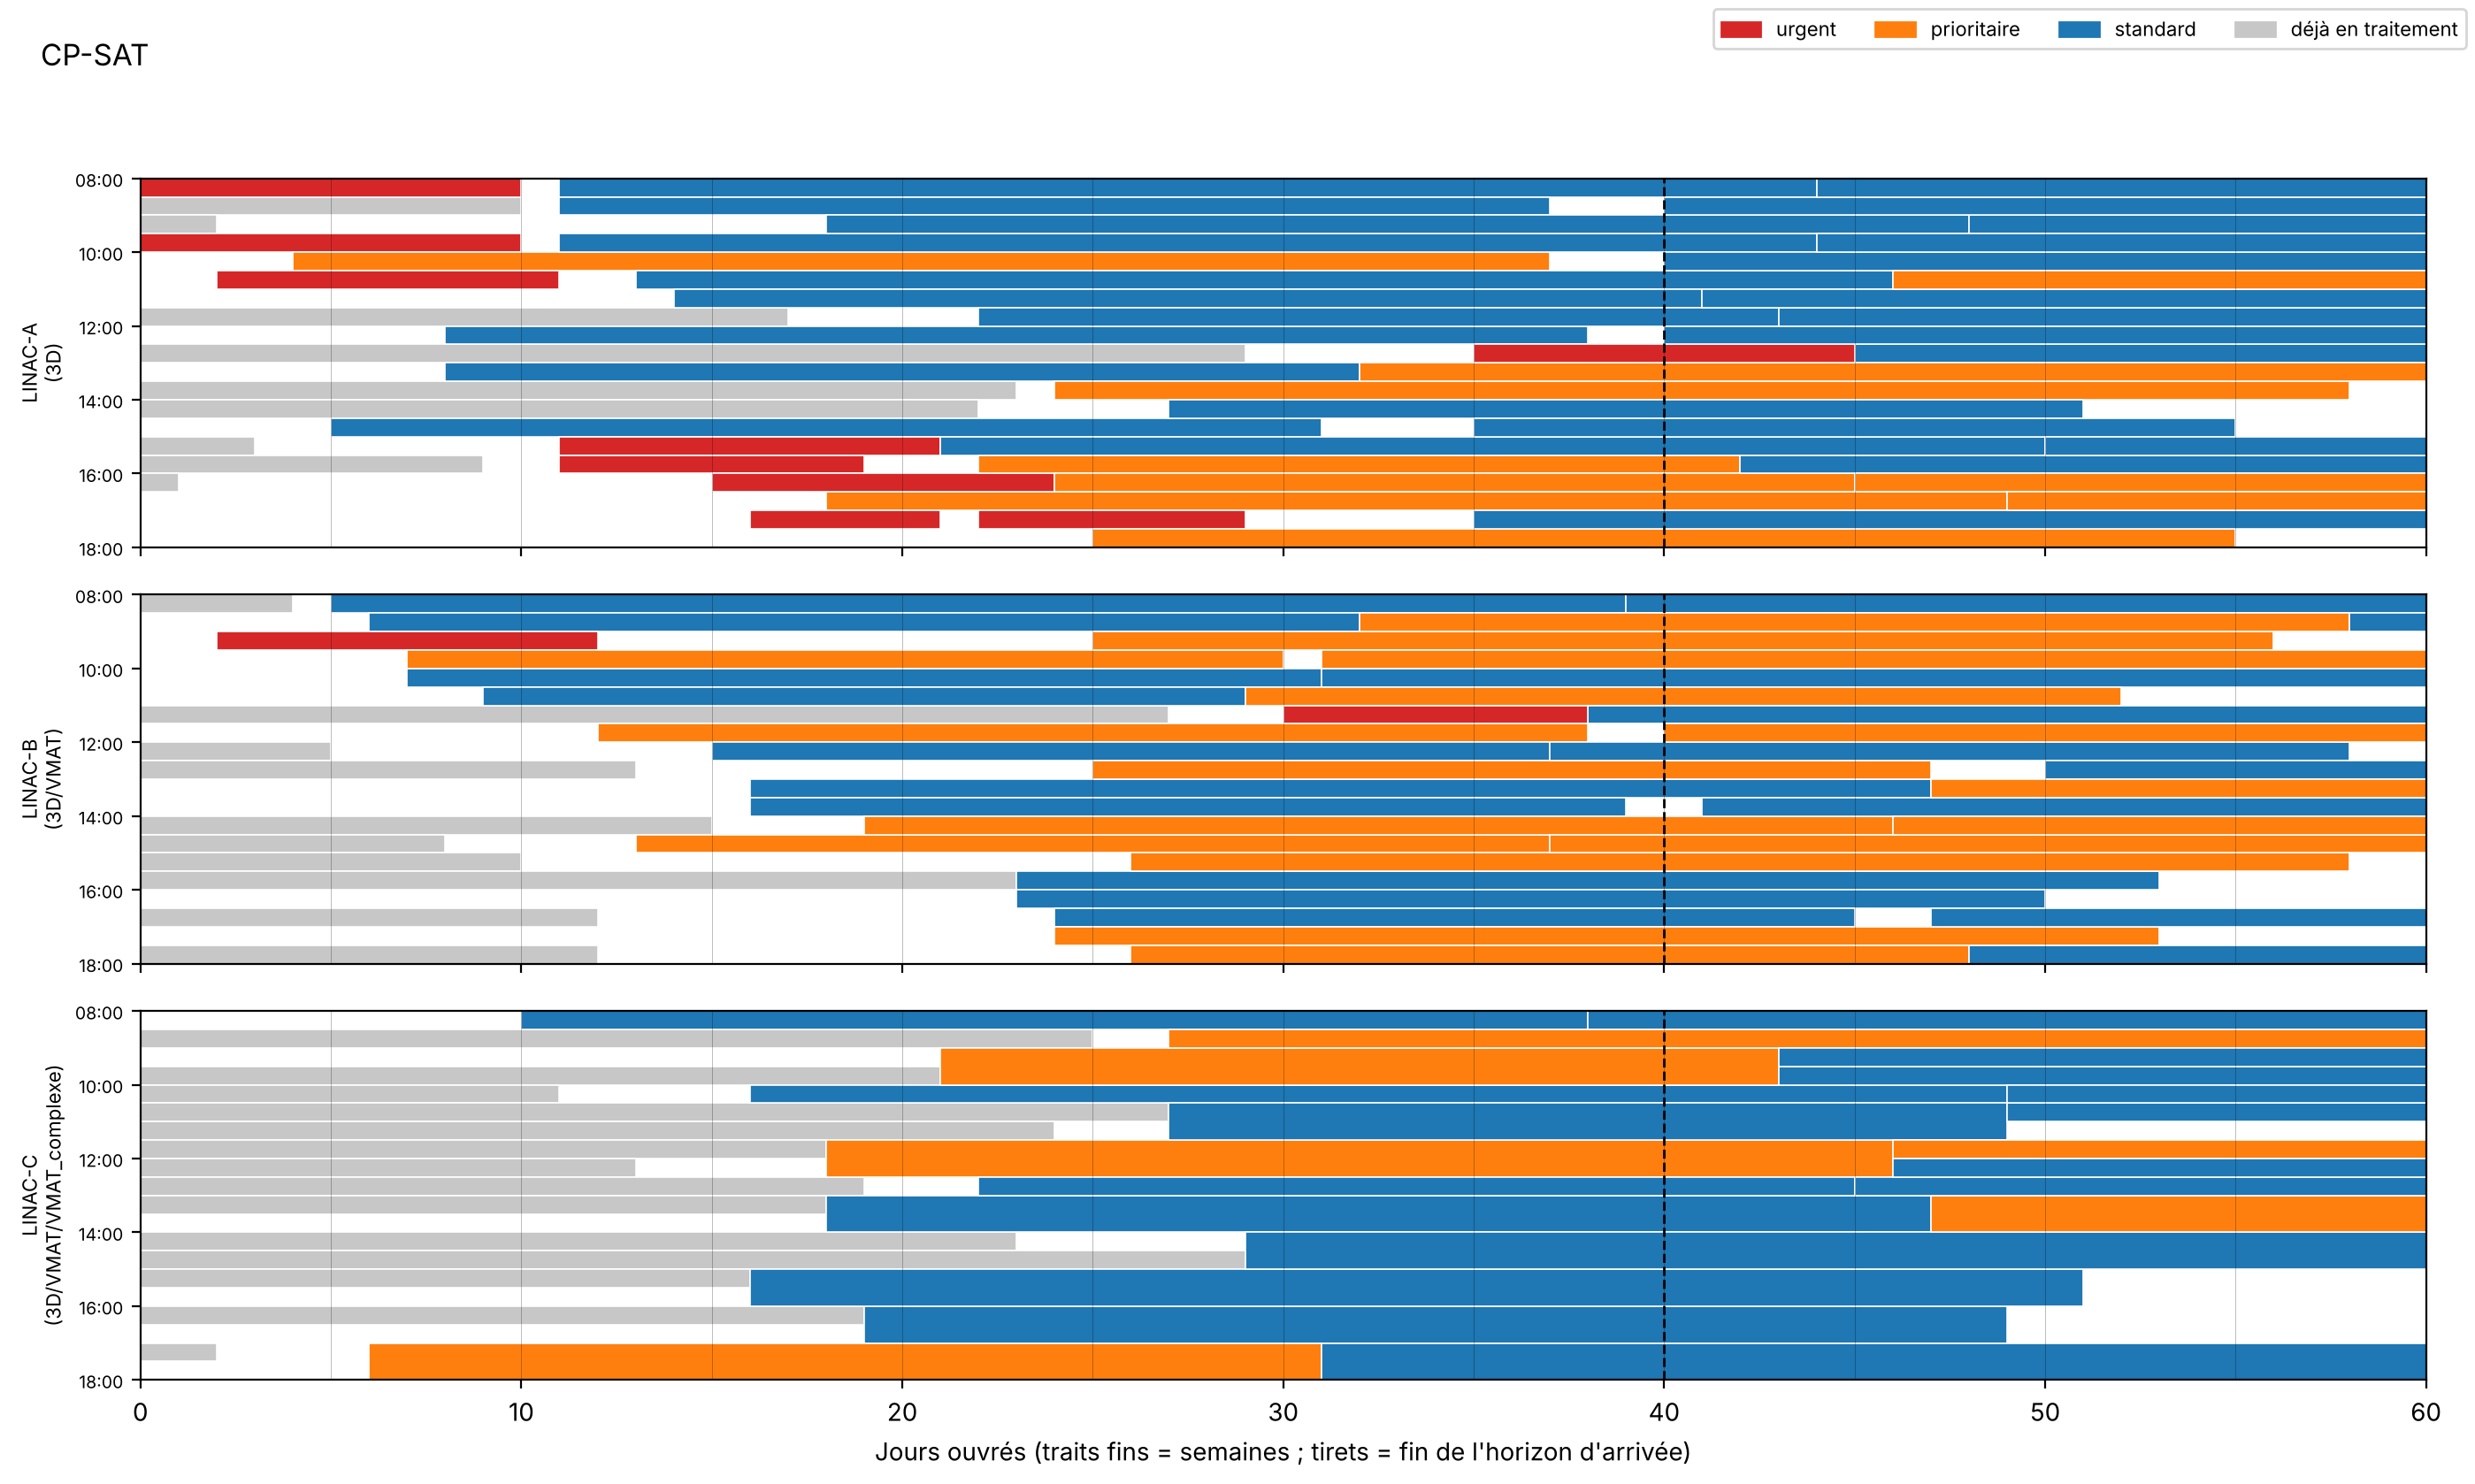

In [5]:
meilleur = min([pl_fcfs, pl_fcfs_prio], key=lambda pl: cout_planning(inst, pl))
res = resoudre_cpsat(inst, temps_limite=30, solution_initiale=meilleur)
print({k: v for k, v in res.items() if k != "planning"})
pl_cpsat = res["planning"]
gantt(inst, pl_cpsat, "CP-SAT");

## 4. Vérificateur indépendant

Il ne réutilise pas le modèle : il déplie chaque planning en **séances individuelles** (patient, jour, machine, créneau) et re-vérifie les règles une à une (nombre de séances, consécutivité, même machine, même créneau, compatibilité, préparation, patients figés, absence de conflit, délais). `tests.py` montre qu'il détecte des plannings volontairement cassés.

In [6]:
plannings = {"FCFS": pl_fcfs, "FCFS+prio": pl_fcfs_prio, "CP-SAT": pl_cpsat}
for nom, pl in plannings.items():
    v = verifier(inst, planning_vers_seances(inst, pl))
    print(f"{nom:10s} valide={v['valide']}  erreurs={len(v['erreurs'])}  dépassements de délai={len(v['avertissements'])}")

FCFS       valide=True  erreurs=0  dépassements de délai=13
FCFS+prio  valide=True  erreurs=0  dépassements de délai=12
CP-SAT     valide=True  erreurs=0  dépassements de délai=3


## 5. Comparaison

In [7]:
res_ind = {}
for nom, pl in plannings.items():
    d = indicateurs(inst, pl); d["cout_objectif"] = cout_planning(inst, pl); res_ind[nom] = d
tableau_comparatif(res_ind)

,FCFS,FCFS+prio,CP-SAT
urgent_n,11.00,11.00,11.00
urgent_attente_moy,1.45,1.18,0.00
urgent_attente_max,9.00,7.00,0.00
urgent_%_dans_delai,81.80,81.80,100.00
prioritaire_n,32.00,32.00,32.00
prioritaire_attente_moy,7.81,7.34,5.47
prioritaire_attente_max,18.00,18.00,22.00
prioritaire_%_dans_delai,65.60,68.80,90.60
standard_n,60.00,60.00,60.00
standard_attente_moy,7.48,7.77,9.30


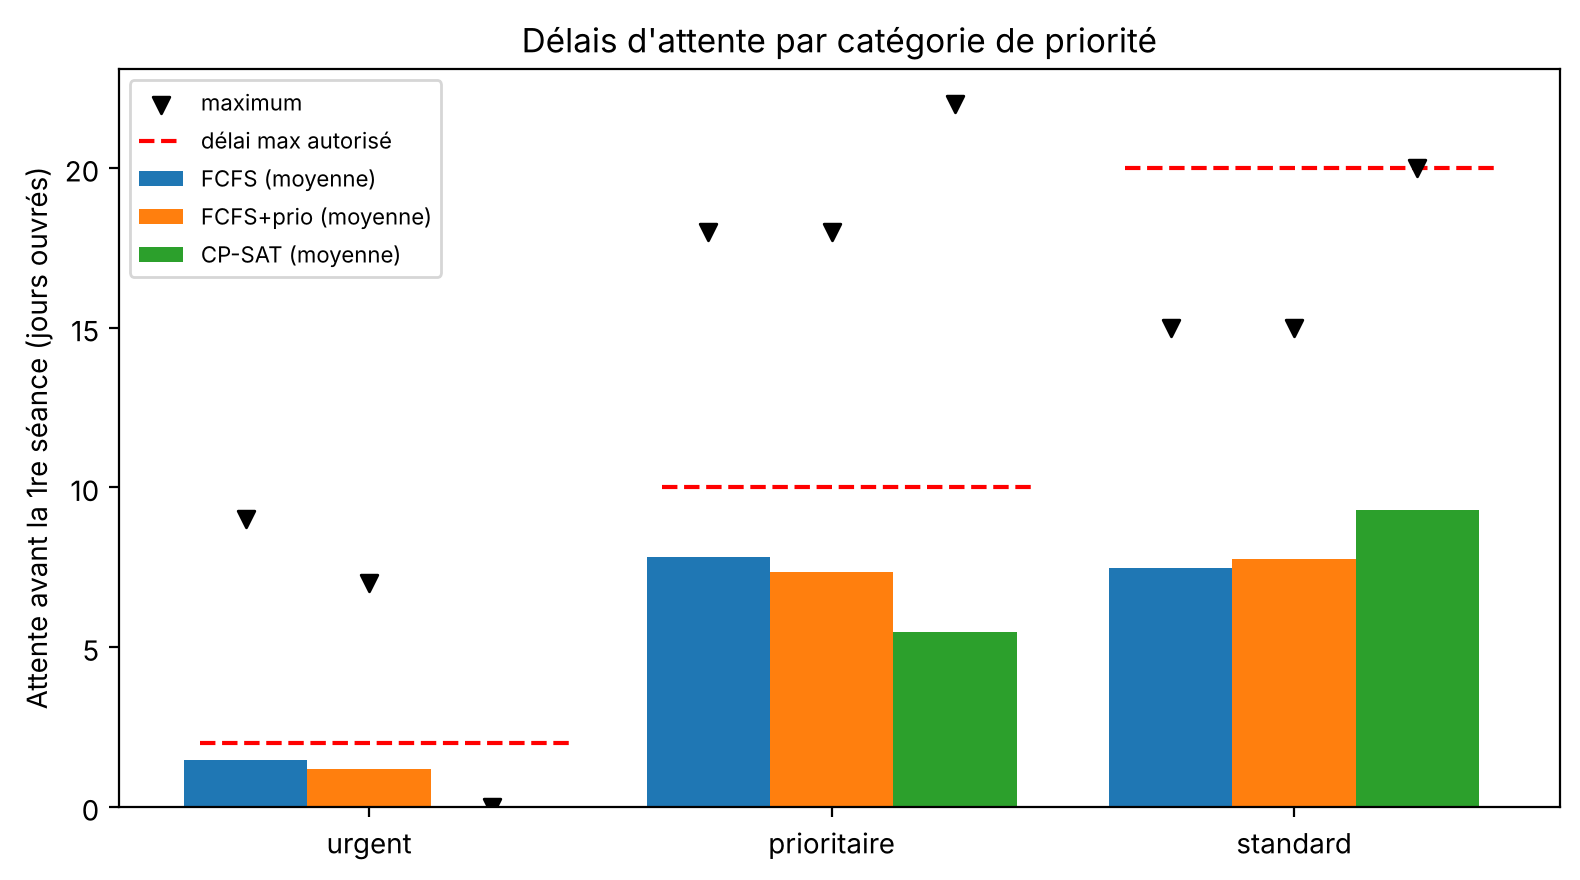

In [8]:
comparaison_attentes(inst, plannings);

## 6. Expériences sur plusieurs instances

Plusieurs graines × plusieurs niveaux de charge (plus long : lancer plutôt `python main.py experiences` dans un terminal).

In [9]:
from main import comparer
lignes = []
for charge in [0.8, 1.0]:
    for g in range(2):
        i = generer_instance(graine=g, charge=charge)
        _, r, _ = comparer(i, temps_limite=10, verbose=False)
        for meth, ind in r.items():
            lignes.append({"charge": charge, "graine": g, "methode": meth, **ind})
df = pd.DataFrame(lignes)
df.groupby(["charge", "methode"])[["urgent_%_dans_delai", "prioritaire_%_dans_delai",
    "standard_%_dans_delai", "global_attente_moy", "occupation_%", "cout_objectif"]].mean().round(1)

urgent_%_dans_delai  prioritaire_%_dans_delai  \
charge methode                                                    
0.8    CP-SAT                   100.0                     100.0   
       FCFS                      85.7                      98.1   
       FCFS+prio                 85.7                      98.1   
1.0    CP-SAT                    79.5                      92.2   
       FCFS                      56.4                      90.6   
       FCFS+prio                 56.4                      92.2   

                  standard_%_dans_delai  global_attente_moy  occupation_%  \
charge methode                                                              
0.8    CP-SAT                     100.0                 4.0          72.6   
       FCFS                       100.0                 4.0          73.1   
       FCFS+prio                  100.0                 4.0          73.0   
1.0    CP-SAT                      97.4                 5.6          83.9   
       FCFS                       100.0                 5.1          85.2   
       FCFS+prio                  100.0                 5.1          85.2   

                  cout_objectif  
charge methode                   
0.8    CP-SAT             452.5  
       FCFS              6300.0  
       FCFS+prio         5291.0  
1.0    CP-SAT           13463.0  
       FCFS             24642.0  
       FCFS+prio        21000.5

## 7. Plan B : une seule machine

In [10]:
inst1 = generer_instance(graine=0, nb_machines=1, charge=1.0)
pl1 = planifier_fcfs(inst1)
r1 = resoudre_cpsat(inst1, temps_limite=10, solution_initiale=pl1)
print(r1["statut"], r1["temps_s"], "s")
tableau_comparatif({"FCFS": indicateurs(inst1, pl1), "CP-SAT": indicateurs(inst1, r1["planning"])})

FEASIBLE 10.0 s


,FCFS,CP-SAT
urgent_n,4.00,4.00
urgent_attente_moy,0.00,0.00
urgent_attente_max,0.00,0.00
urgent_%_dans_delai,100.00,100.00
prioritaire_n,8.00,8.00
prioritaire_attente_moy,8.88,3.12
prioritaire_attente_max,18.00,4.00
prioritaire_%_dans_delai,50.00,100.00
standard_n,25.00,25.00
standard_attente_moy,7.24,9.36


## 8. Pistes d'analyse et extensions

- **Compromis** : CP-SAT fait passer urgents et prioritaires devant ; les standards attendent un peu plus (parfois beaucoup pour un patient → ajouter un terme d'équité, ex. minimiser l'attente maximale).
- **Avantage injuste ?** CP-SAT connaît toutes les arrivées à l'avance (hors-ligne), FCFS non. → Extension **horizon glissant** : chaque jour, on replanifie uniquement les patients arrivés, sans toucher ceux qui ont commencé.
- **Panne de machine** : bloquer une machine k jours (rectangle fixe) et replanifier les patients concernés.
- **Préférences horaires** : coût si le créneau est hors de la plage souhaitée (matin / après-midi).
- **Borne inférieure** faible (gap élevé) : discuter, essayer `delai_strict=True`, ou des contraintes redondantes de capacité cumulée.